<a href="https://colab.research.google.com/github/Sanhith30/deepLearning-csa4704/blob/main/Lab%20Exp/CO3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Missing values before: 88
Missing values after : 0
                         demand
2023-01-01 00:00:00  357.450712
2023-01-01 01:00:00  353.094542
2023-01-01 02:00:00  379.926279
2023-01-01 03:00:00  416.951573
2023-01-01 04:00:00  421.717222
X shape: (8736, 24, 1) y shape: (8736,)
Train: (6984, 24, 1) Test: (1752, 24, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
99/99 - 3s - 30ms/step - loss: 0.1322 - val_loss: 0.0281
Epoch 2/15
99/99 - 1s - 6ms/step - loss: 0.0070 - val_loss: 0.0042
Epoch 3/15
99/99 - 1s - 6ms/step - loss: 0.0025 - val_loss: 0.0032
Epoch 4/15
99/99 - 1s - 6ms/step - loss: 0.0019 - val_loss: 0.0026
Epoch 5/15
99/99 - 1s - 6ms/step - loss: 0.0016 - val_loss: 0.0022
Epoch 6/15
99/99 - 1s - 6ms/step - loss: 0.0015 - val_loss: 0.0018
Epoch 7/15
99/99 - 1s - 6ms/step - loss: 0.0014 - val_loss: 0.0016
Epoch 8/15
99/99 - 1s - 6ms/step - loss: 0.0013 - val_loss: 0.0015
Epoch 9/15
99/99 - 1s - 6ms/step - loss: 0.0012 - val_loss: 0.0014
Epoch 10/15
99/99 - 1s - 9ms/step - loss: 0.0012 - val_loss: 0.0014
Epoch 11/15
99/99 - 1s - 15ms/step - loss: 0.0012 - val_loss: 0.0013
Epoch 12/15
99/99 - 1s - 14ms/step - loss: 0.0012 - val_loss: 0.0013
Epoch 13/15
99/99 - 2s - 19ms/step - loss: 0.0012 - val_loss: 0.0013
Epoch 14/15
99/99 - 1s - 6ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 15/15
99/99 - 1s - 6ms/step - loss: 0.0011 - va

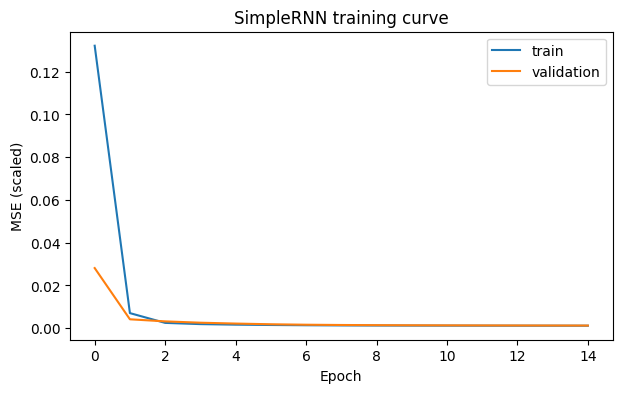

Test MAE  = 15.38 MW
Test RMSE = 19.55 MW


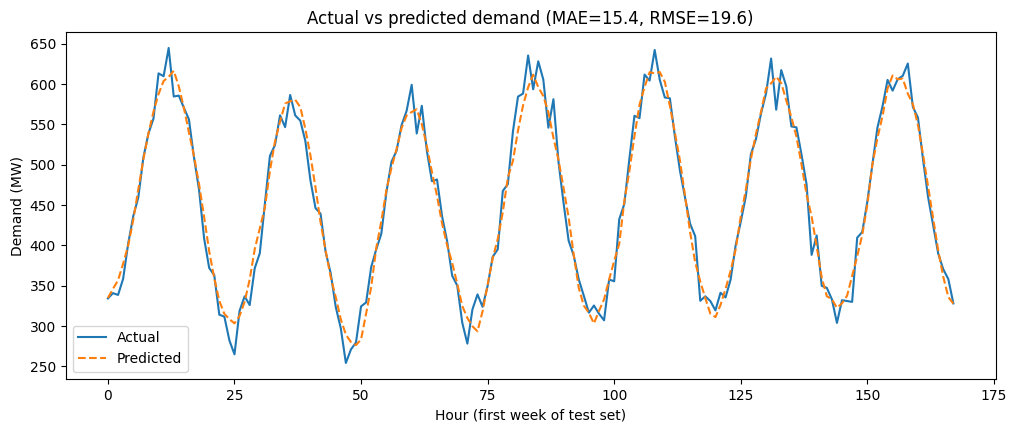

In [1]:
"""Experiment 13: Sequential Dataset Preparation and RNN Prediction (hourly electricity demand)"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42); tf.random.set_seed(42)

# ---------------- Task 1: load series, handle missing values, scale ----------------
# Synthetic hourly demand (MW) for one year: daily cycle + weekly cycle + seasonal trend + noise
hours = pd.date_range("2023-01-01", periods=8760, freq="h")
t = np.arange(8760)
demand = (500 + 150 * np.sin(2 * np.pi * (t % 24 - 6) / 24)           # daily peak in the evening
          + 40 * (hours.dayofweek < 5)                                 # weekdays use more
          + 80 * np.sin(2 * np.pi * t / 8760)                          # seasonal trend
          + np.random.normal(0, 15, 8760))
df = pd.DataFrame({"demand": demand}, index=hours)
df.loc[df.sample(frac=0.01, random_state=1).index, "demand"] = np.nan   # 1% missing values
# To use your own file:  df = pd.read_csv("demand.csv", parse_dates=["time"], index_col="time")
print("Missing values before:", df["demand"].isna().sum())
df["demand"] = df["demand"].interpolate(method="time")                  # fill gaps
print("Missing values after :", df["demand"].isna().sum())
print(df.head())

split = int(0.8 * len(df))                                              # chronological split point
scaler = MinMaxScaler().fit(df.iloc[:split])                            # fit on TRAIN only (no leakage)
scaled = scaler.transform(df).ravel()

# ---------------- Task 2: sliding windows (24 past hours -> next hour) ----------------
WINDOW = 24
X, y = [], []
for i in range(len(scaled) - WINDOW):
    X.append(scaled[i:i + WINDOW]); y.append(scaled[i + WINDOW])
X = np.array(X)[..., np.newaxis]            # (samples, 24, 1)
y = np.array(y)
print("X shape:", X.shape, "y shape:", y.shape)

# ---------------- Task 3: chronological train/test split (no shuffling) ----------------
cut = split - WINDOW
X_train, y_train, X_test, y_test = X[:cut], y[:cut], X[cut:], y[cut:]
print("Train:", X_train.shape, "Test:", X_test.shape)

# ---------------- Task 4: SimpleRNN ----------------
model = keras.Sequential([layers.Input((WINDOW, 1)), layers.SimpleRNN(32), layers.Dense(1)])
model.compile(optimizer=keras.optimizers.Adam(0.001), loss="mse")
model.summary()
hist = model.fit(X_train, y_train, validation_split=0.1, epochs=15, batch_size=64, verbose=2)

plt.figure(figsize=(7, 4))
plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("MSE (scaled)"); plt.title("SimpleRNN training curve"); plt.legend(); plt.show()

# ---------------- Task 5: actual vs predicted, MAE & RMSE ----------------
pred = model.predict(X_test, verbose=0)
pred_mw = scaler.inverse_transform(pred).ravel()                        # back to MW
actual_mw = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
mae = mean_absolute_error(actual_mw, pred_mw)
rmse = np.sqrt(mean_squared_error(actual_mw, pred_mw))
print(f"Test MAE  = {mae:.2f} MW")
print(f"Test RMSE = {rmse:.2f} MW")

plt.figure(figsize=(12, 4.5))
plt.plot(actual_mw[:168], label="Actual"); plt.plot(pred_mw[:168], "--", label="Predicted")
plt.xlabel("Hour (first week of test set)"); plt.ylabel("Demand (MW)")
plt.title(f"Actual vs predicted demand (MAE={mae:.1f}, RMSE={rmse:.1f})"); plt.legend(); plt.show()

W_xh (input -> hidden): (4, 3)
[[-0.363  0.512  0.679]
 [-0.405  0.65   0.292]
 [-0.682 -0.325  0.537]
 [-0.338  0.34  -0.568]]
W_hh (hidden -> hidden): (3, 3)
[[-0.011 -0.722  0.692]
 [ 0.559 -0.579 -0.594]
 [-0.829 -0.38  -0.41 ]]
W_hy (hidden -> output): (3, 2)
[[-0.287  0.206]
 [-0.917 -0.791]
 [ 0.642 -0.015]]

Manual hidden states:
                 unit1   unit2   unit3
h1 (I)         0.3633  0.2357  0.8482
h2 (love)     -0.7116 -0.9890  0.7810
h3 (deep)     -0.9065 -0.3675  0.9540
h4 (learning) -0.8057 -0.5737  0.1022
h5 (models)   -0.2008  0.3799 -0.7357
Matches Keras hidden states: True
Matches Keras outputs      : True


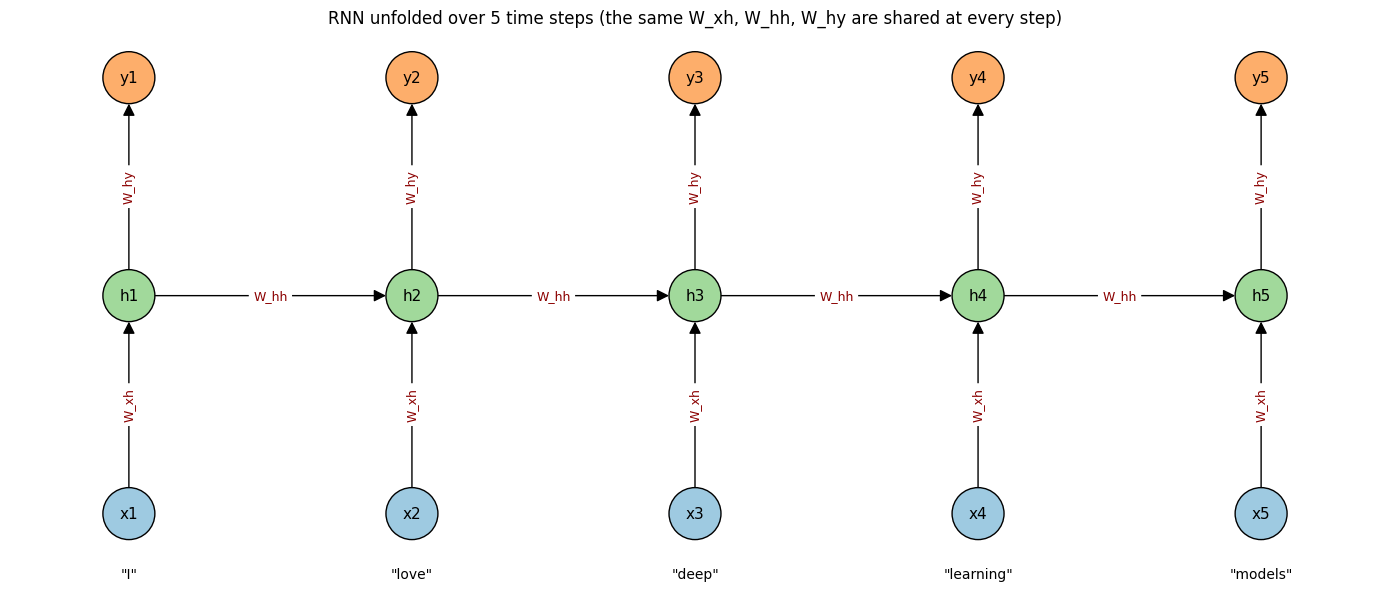

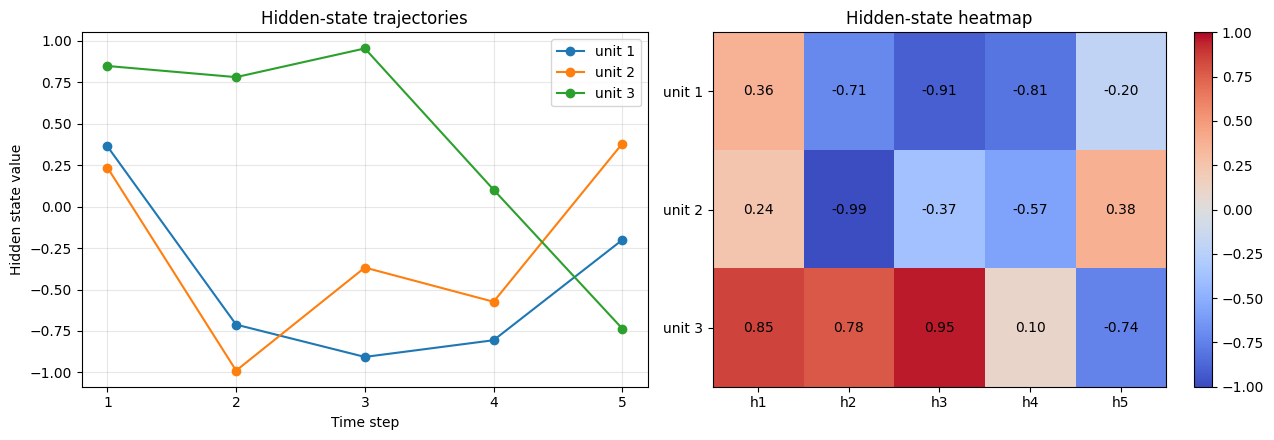

In [2]:
"""Experiment 14: Unfolded RNN Architecture Visualization"""
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(1); tf.random.set_seed(1)

words = ["I", "love", "deep", "learning", "models"]       # 5-word sentence
T, EMB, UNITS, OUT = 5, 4, 3, 2
emb = np.random.randn(T, EMB)                              # a fixed 4-D vector for each word
X = emb[np.newaxis].astype("float32")                      # shape (1, 5, 4)

# ---------------- Task 1: build SimpleRNN and extract weights ----------------
inp = keras.Input((T, EMB))
rnn = layers.SimpleRNN(UNITS, activation="tanh", return_sequences=True, name="rnn")
h_seq = rnn(inp)
y_seq = layers.Dense(OUT, name="out")(h_seq)               # y_t = W_hy h_t + b_y at every step
model = keras.Model(inp, y_seq)
rnn_model = keras.Model(inp, h_seq)

W_xh, W_hh, b_h = rnn.get_weights()                        # input, recurrent kernels and bias
W_hy, b_y = model.get_layer("out").get_weights()
print("W_xh (input -> hidden):", W_xh.shape); print(np.round(W_xh, 3))
print("W_hh (hidden -> hidden):", W_hh.shape); print(np.round(W_hh, 3))
print("W_hy (hidden -> output):", W_hy.shape); print(np.round(W_hy, 3))

# ---------------- Task 2: manual hidden states vs Keras ----------------
h = np.zeros(UNITS)
manual_h, manual_y = [], []
for t in range(T):
    h = np.tanh(X[0, t] @ W_xh + h @ W_hh + b_h)           # h_t = tanh(x_t W_xh + h_{t-1} W_hh + b)
    manual_h.append(h); manual_y.append(h @ W_hy + b_y)    # y_t = h_t W_hy + b_y
manual_h, manual_y = np.array(manual_h), np.array(manual_y)
keras_h = rnn_model.predict(X, verbose=0)[0]
keras_y = model.predict(X, verbose=0)[0]

table = pd.DataFrame(manual_h, index=[f"h{t+1} ({w})" for t, w in enumerate(words)],
                     columns=[f"unit{u+1}" for u in range(UNITS)])
print("\nManual hidden states:\n", table.round(4))
print("Matches Keras hidden states:", np.allclose(manual_h, keras_h, atol=1e-5))
print("Matches Keras outputs      :", np.allclose(manual_y, keras_y, atol=1e-5))

# ---------------- Task 3 & 4: unfolded graph with NetworkX ----------------
G = nx.DiGraph()
pos = {}
for t in range(1, T + 1):
    G.add_node(f"x{t}"); G.add_node(f"h{t}"); G.add_node(f"y{t}")
    pos[f"x{t}"], pos[f"h{t}"], pos[f"y{t}"] = (t * 2, 0), (t * 2, 1.5), (t * 2, 3)
    G.add_edge(f"x{t}", f"h{t}", label="W_xh")
    G.add_edge(f"h{t}", f"y{t}", label="W_hy")
    if t > 1:
        G.add_edge(f"h{t-1}", f"h{t}", label="W_hh")

plt.figure(figsize=(14, 6))
colors = ["#9ecae1" if n[0] == "x" else "#a1d99b" if n[0] == "h" else "#fdae6b" for n in G.nodes]
nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=1400, edgecolors="k")
nx.draw_networkx_labels(G, pos, font_size=11)
nx.draw_networkx_edges(G, pos, arrowsize=18, node_size=1400)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=9,
                             font_color="darkred", label_pos=0.5)
for t, w in enumerate(words, start=1):
    plt.text(t * 2, -0.45, f'"{w}"', ha="center", fontsize=10)
plt.title("RNN unfolded over 5 time steps (the same W_xh, W_hh, W_hy are shared at every step)")
plt.axis("off"); plt.tight_layout(); plt.show()

# ---------------- Task 5: hidden-state values across time ----------------
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for u in range(UNITS):
    ax[0].plot(range(1, T + 1), manual_h[:, u], "o-", label=f"unit {u+1}")
ax[0].set_xticks(range(1, T + 1)); ax[0].set_xlabel("Time step"); ax[0].set_ylabel("Hidden state value")
ax[0].set_title("Hidden-state trajectories"); ax[0].legend(); ax[0].grid(alpha=0.3)
im = ax[1].imshow(manual_h.T, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax[1].set_xticks(range(T)); ax[1].set_xticklabels([f"h{t+1}" for t in range(T)])
ax[1].set_yticks(range(UNITS)); ax[1].set_yticklabels([f"unit {u+1}" for u in range(UNITS)])
for t in range(T):
    for u in range(UNITS):
        ax[1].text(t, u, f"{manual_h[t, u]:.2f}", ha="center", va="center")
ax[1].set_title("Hidden-state heatmap"); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

T= 10 | tanh: grad at t=1 / grad at t=T = 2.27e-01 | ReLU: 4.25e-02
T= 50 | tanh: grad at t=1 / grad at t=T = 2.17e-02 | ReLU: 1.22e-04
T=100 | tanh: grad at t=1 / grad at t=T = 9.55e-05 | ReLU: 3.40e-13


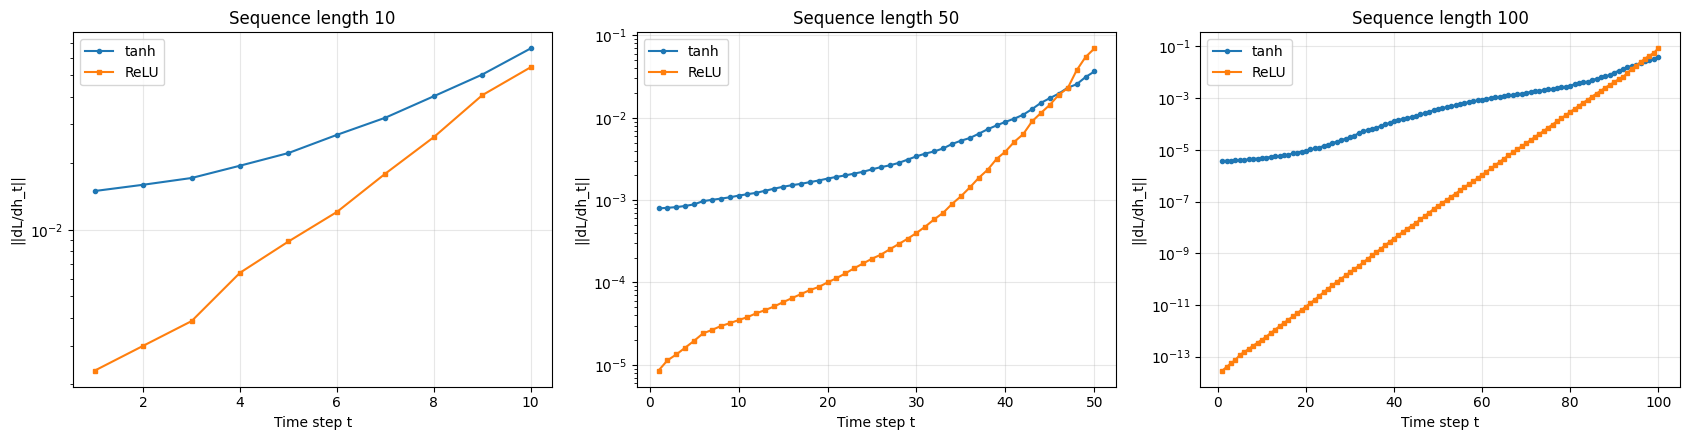

tanh, default W_hh (orthogonal)               grad(t=1)=2.636e-05  grad(t=T)=3.449e-02
ReLU, default W_hh (orthogonal)               grad(t=1)=3.256e-11  grad(t=T)=1.280e-01
linear, W_hh x0.9  -> VANISHING               grad(t=1)=4.167e-06  grad(t=T)=1.412e-01
linear, W_hh x1.0  -> stable                  grad(t=1)=5.851e-02  grad(t=T)=5.851e-02
linear, W_hh x1.1  -> EXPLODING               grad(t=1)=1.592e+07  grad(t=T)=1.271e+03


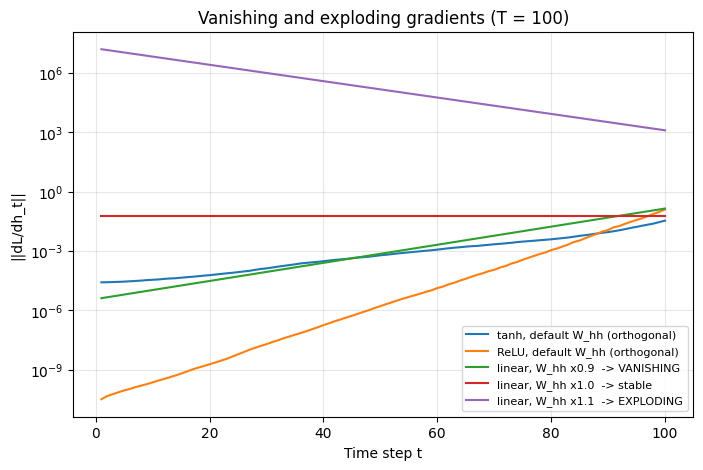


Explanation:
 - Gradients flow backwards from the loss at step T to earlier steps, multiplying by W_hh^T and
   the activation derivative at every step.
 - If this product has norm < 1 (e.g. tanh whose derivative <= 1, or small W_hh) the gradient shrinks
   exponentially towards early steps -> VANISHING: the RNN cannot learn long-range dependencies.
 - If the norm > 1 (e.g. large W_hh, or ReLU's unbounded derivative of 1) it grows exponentially -> EXPLODING: unstable updates / NaN.
 - The effect grows with sequence length (compare T = 10, 50, 100).


In [3]:
"""Experiment 15: BPTT Flow and Gradient Analysis (vanishing / exploding gradients)"""
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42); tf.random.set_seed(42)

# ---------------- Data: 3 years of daily closing prices (synthetic geometric random walk) ----------------
n_days = 3 * 252
returns = np.random.normal(0.0004, 0.012, n_days)
price = 1000 * np.exp(np.cumsum(returns))
price = (price - price.mean()) / price.std()          # standardise
# To use real data:  price = pd.read_csv("index.csv")["Close"].values  (then standardise)

def make_windows(series, T, n=32):
    idx = np.random.randint(0, len(series) - T - 1, n)
    X = np.stack([series[i:i + T] for i in idx])[..., None].astype("float32")
    y = np.array([series[i + T] for i in idx], dtype="float32").reshape(-1, 1)
    return tf.constant(X), tf.constant(y)

# ---------------- Tasks 1 & 2: BPTT with tf.GradientTape ----------------
def gradient_norms(T, activation="tanh", units=32, rec_scale=1.0, seed=0):
    """Return ||dL/dh_t|| for t = 1..T (averaged over a mini-batch)."""
    tf.random.set_seed(seed); np.random.seed(seed)
    cell = layers.SimpleRNNCell(units, activation=activation)     # the recurrent cell of a SimpleRNN
    head = layers.Dense(1)
    X, y = make_windows(price, T)
    cell.build((None, 1)); head.build((None, units))
    cell.recurrent_kernel.assign(cell.recurrent_kernel * rec_scale)  # optional scaling of W_hh
    with tf.GradientTape() as tape:
        h = tf.zeros((X.shape[0], units))
        hs = []
        for t in range(T):                                       # unrolled forward pass (time loop)
            h, _ = cell(X[:, t, :], [h])
            hs.append(h)
        loss = tf.reduce_mean(tf.square(head(h) - y))             # loss depends on the LAST hidden state
    grads = tape.gradient(loss, hs)                               # dL/dh_t for every time step (BPTT)
    return np.array([tf.reduce_mean(tf.norm(g, axis=1)).numpy() for g in grads])

# ---------------- Task 3 & 4: gradient norm vs time step, tanh vs ReLU ----------------
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, T in zip(ax, [10, 50, 100]):
    g_tanh = gradient_norms(T, "tanh")
    g_relu = gradient_norms(T, "relu")
    a.plot(range(1, T + 1), g_tanh, "o-", ms=3, label="tanh")
    a.plot(range(1, T + 1), g_relu, "s-", ms=3, label="ReLU")
    a.set_yscale("log"); a.set_xlabel("Time step t"); a.set_ylabel("||dL/dh_t||")
    a.set_title(f"Sequence length {T}"); a.legend(); a.grid(alpha=0.3)
    print(f"T={T:3d} | tanh: grad at t=1 / grad at t=T = {g_tanh[0]/g_tanh[-1]:.2e} | "
          f"ReLU: {g_relu[0]/g_relu[-1]:.2e}")
plt.tight_layout(); plt.show()

# ---------------- Task 5: vanishing vs exploding ----------------
# A linear activation isolates the effect of W_hh: the gradient is multiplied by ~(scale)^k after k steps.
T = 100
plt.figure(figsize=(8, 5))
for act, scale, label in [("tanh", 1.0, "tanh, default W_hh (orthogonal)"),
                          ("relu", 1.0, "ReLU, default W_hh (orthogonal)"),
                          ("linear", 0.9, "linear, W_hh x0.9  -> VANISHING"),
                          ("linear", 1.0, "linear, W_hh x1.0  -> stable"),
                          ("linear", 1.1, "linear, W_hh x1.1  -> EXPLODING")]:
    g = gradient_norms(T, act, rec_scale=scale)
    plt.plot(range(1, T + 1), g, label=label)
    print(f"{label:45s} grad(t=1)={g[0]:.3e}  grad(t=T)={g[-1]:.3e}")
plt.yscale("log"); plt.xlabel("Time step t"); plt.ylabel("||dL/dh_t||")
plt.title("Vanishing and exploding gradients (T = 100)"); plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

print("""
Explanation:
 - Gradients flow backwards from the loss at step T to earlier steps, multiplying by W_hh^T and
   the activation derivative at every step.
 - If this product has norm < 1 (e.g. tanh whose derivative <= 1, or small W_hh) the gradient shrinks
   exponentially towards early steps -> VANISHING: the RNN cannot learn long-range dependencies.
 - If the norm > 1 (e.g. large W_hh, or ReLU's unbounded derivative of 1) it grows exponentially -> EXPLODING: unstable updates / NaN.
 - The effect grows with sequence length (compare T = 10, 50, 100).""")


                 orders
2023-01-01  1269.868566
2023-01-02   994.769428
2023-01-03  1026.507542
2023-01-04  1061.821194
2023-01-05   991.833865
Train: (554, 30, 1) Test: (146, 30, 1)


SimpleRNN  time= 32.4s  MAE=  54.84  RMSE=  67.92  MAPE= 4.06%
LSTM       time= 26.5s  MAE=  45.35  RMSE=  55.61  MAPE= 3.39%


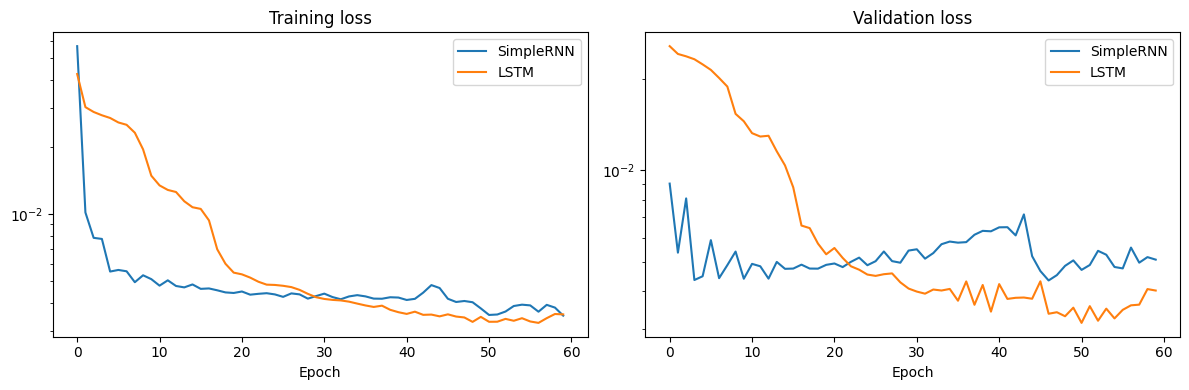

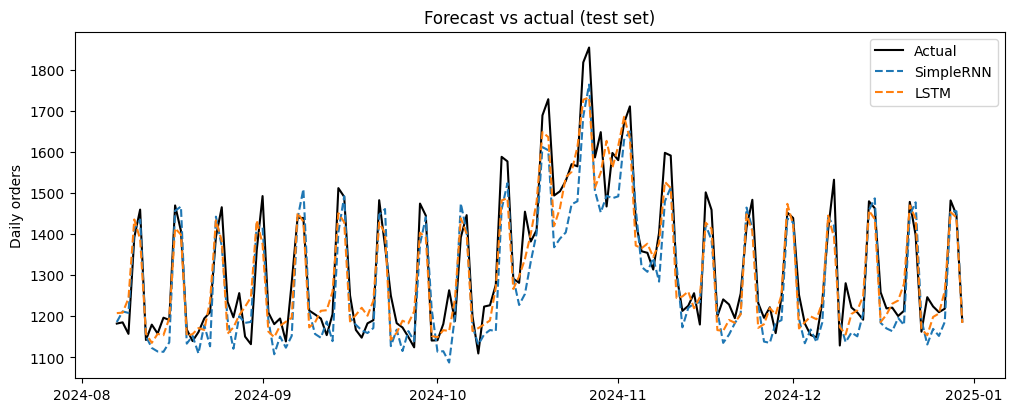


            Params  Train loss  Val loss  Train time (s)      MAE     RMSE  MAPE (%)
Model                                                                              
SimpleRNN    4289      0.0035    0.0051            32.4  54.8419  67.9245    4.0607
LSTM        16961      0.0035    0.0040            26.5  45.3506  55.6050    3.3869


In [4]:
"""Experiment 16: LSTM and RNN Performance Comparison (daily food-order forecasting)"""
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42); tf.random.set_seed(42)

# ---------------- Data: 2 years of daily orders with weekly + festival patterns ----------------
days = pd.date_range("2023-01-01", periods=730, freq="D")
t = np.arange(730)
orders = (1000 + 0.3 * t                                                  # growth trend
          + 250 * (days.dayofweek >= 5)                                    # weekend peak
          + 400 * np.exp(-((t % 365 - 300) ** 2) / (2 * 8 ** 2))           # festival season (~day 300)
          + 200 * np.exp(-((t % 365 - 100) ** 2) / (2 * 6 ** 2))           # second festival (~day 100)
          + np.random.normal(0, 40, 730))
df = pd.DataFrame({"orders": orders}, index=days)
# For the airline passengers dataset use:  df = pd.read_csv("airline-passengers.csv", index_col=0)
print(df.head())

split = int(0.8 * len(df))
scaler = MinMaxScaler().fit(df.iloc[:split])
scaled = scaler.transform(df).ravel()

# ---------------- Task 1: 30-day look-back window ----------------
WINDOW = 30
X, y = [], []
for i in range(len(scaled) - WINDOW):
    X.append(scaled[i:i + WINDOW]); y.append(scaled[i + WINDOW])
X = np.array(X)[..., None]; y = np.array(y)
cut = split - WINDOW
X_train, y_train, X_test, y_test = X[:cut], y[:cut], X[cut:], y[cut:]
print("Train:", X_train.shape, "Test:", X_test.shape)

# ---------------- Task 2: same number of units ----------------
UNITS, EPOCHS = 64, 60
def build(cell):
    m = keras.Sequential([layers.Input((WINDOW, 1)), cell(UNITS), layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(0.005), loss="mse")
    return m

results, preds, histories = [], {}, {}
actual = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
for name, cell in [("SimpleRNN", layers.SimpleRNN), ("LSTM", layers.LSTM)]:
    tf.random.set_seed(42)
    model = build(cell)
    t0 = time.time()
    h = model.fit(X_train, y_train, validation_split=0.15, epochs=EPOCHS, batch_size=32, verbose=0)
    train_time = time.time() - t0
    p = scaler.inverse_transform(model.predict(X_test, verbose=0)).ravel()
    mae = mean_absolute_error(actual, p)
    rmse = np.sqrt(mean_squared_error(actual, p))
    mape = np.mean(np.abs((actual - p) / actual)) * 100                  # Task 4
    results.append({"Model": name, "Params": model.count_params(), "Train loss": h.history["loss"][-1],
                    "Val loss": h.history["val_loss"][-1], "Train time (s)": round(train_time, 1),
                    "MAE": mae, "RMSE": rmse, "MAPE (%)": mape})
    preds[name] = p; histories[name] = h.history
    print(f"{name:10} time={train_time:5.1f}s  MAE={mae:7.2f}  RMSE={rmse:7.2f}  MAPE={mape:5.2f}%")

# ---------------- Task 3: loss comparison ----------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    ax[0].plot(h["loss"], label=name); ax[1].plot(h["val_loss"], label=name)
ax[0].set_title("Training loss"); ax[1].set_title("Validation loss")
for a in ax:
    a.set_xlabel("Epoch"); a.set_yscale("log"); a.legend()
plt.tight_layout(); plt.show()

# ---------------- Task 5: forecast plot and results table ----------------
plt.figure(figsize=(12, 4.5))
plt.plot(df.index[-len(actual):], actual, "k", label="Actual")
for name, p in preds.items():
    plt.plot(df.index[-len(actual):], p, "--", label=name)
plt.ylabel("Daily orders"); plt.title("Forecast vs actual (test set)"); plt.legend(); plt.show()

table = pd.DataFrame(results).set_index("Model")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", None)
print("\n", table.round(4))

Corpus length: 100000 | vocabulary size: 50

No clipping: first NaN loss at step 7
Gradient spike steps (norm > 10x early median): [6]
Max finite gradient norm: 396326961152.00

Setting           final loss  max grad norm  NaN?
No clipping              nan       3.96e+11  True
clipnorm=0.5          2.6274       1.72e+03 False
clipnorm=1.0          2.4933       1.16e+04 False
clipnorm=5.0          2.4659       1.42e+04 False
clipvalue=0.05        2.8221       2.94e+06 False
clipvalue=0.5         3.0343       4.25e+15 False


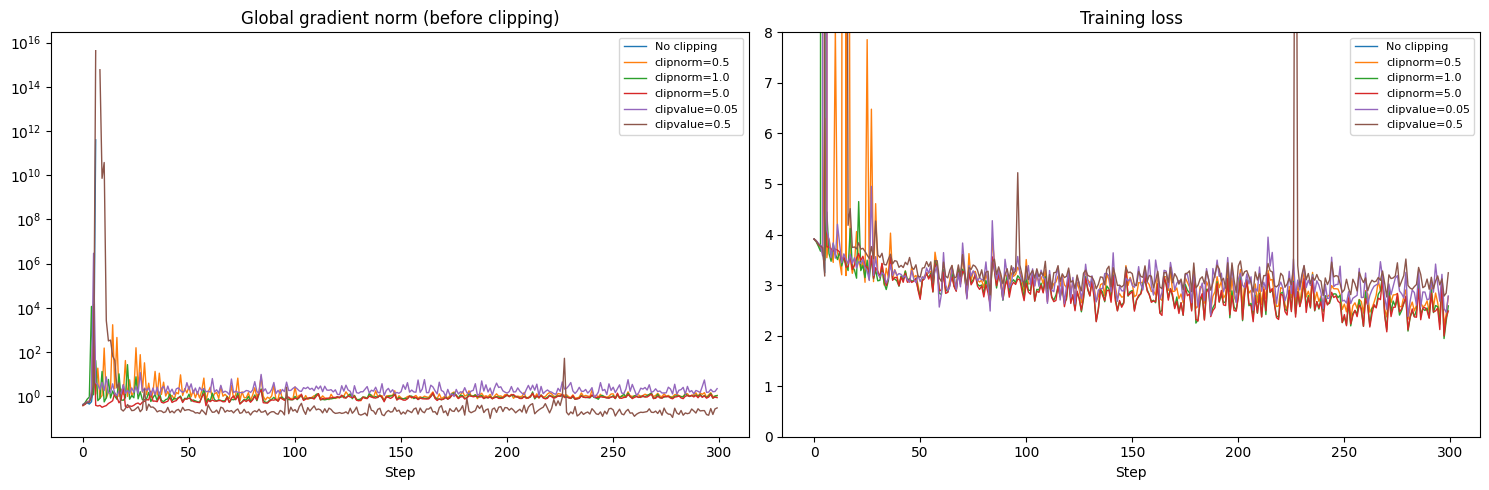


Recommended setting: clipnorm=5.0 (lowest final loss = 2.4659).
Rule of thumb: choose clipnorm near the typical (median) healthy gradient norm; values of 1-5 are common for RNNs. Too small slows learning, too large does not prevent spikes.


In [5]:
"""Experiment 17: RNN Gradient Analysis and Gradient Clipping (character-level text model)"""
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---------------- Data: public-domain novel (Alice in Wonderland, Project Gutenberg) ----------------
URL = "https://www.gutenberg.org/files/11/11-0.txt"
FALLBACK = ("alice was beginning to get very tired of sitting by her sister on the bank, and of having "
            "nothing to do: once or twice she had peeped into the book her sister was reading, but it had "
            "no pictures or conversations in it, and what is the use of a book, thought alice, without "
            "pictures or conversations? ") * 60

def load_text():
    if os.path.exists("novel.txt"):                                   # your own text file
        return open("novel.txt", encoding="utf-8", errors="ignore").read()
    try:
        return urllib.request.urlopen(URL, timeout=15).read().decode("utf-8", errors="ignore")
    except Exception as e:
        print("WARNING: could not download the novel (", e, ") -> using a short built-in text instead.")
        return FALLBACK

text = load_text().lower()[:100000]
chars = sorted(set(text)); c2i = {c: i for i, c in enumerate(chars)}
data = np.array([c2i[c] for c in text]); V = len(chars)
print("Corpus length:", len(text), "| vocabulary size:", V)

SEQ, BATCH, STEPS, LR = 40, 32, 300, 0.5      # deliberately high learning rate (plain SGD)

def get_batch(rng):
    idx = rng.randint(0, len(data) - SEQ - 1, BATCH)
    x = np.stack([data[i:i + SEQ] for i in idx]); y = data[idx + SEQ]   # predict the next character
    return tf.constant(x), tf.constant(y)

def build():
    return keras.Sequential([layers.Input((SEQ,)), layers.Embedding(V, 32),
                             layers.SimpleRNN(128, activation="relu"), layers.Dense(V)])

loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

def train(mode=None, thr=None):
    tf.random.set_seed(0); rng = np.random.RandomState(0)               # identical start & batches for every run
    model = build(); opt = keras.optimizers.SGD(LR)
    norms, losses = [], []
    for step in range(STEPS):
        x, y = get_batch(rng)
        with tf.GradientTape() as tape:
            loss = loss_fn(y, model(x, training=True))
        grads = tape.gradient(loss, model.trainable_variables)
        gnorm = float(tf.linalg.global_norm(grads))                     # Task 1: log global gradient norm
        if mode == "norm":                                              # clipnorm: rescale if norm > thr
            grads, _ = tf.clip_by_global_norm(grads, thr)
        elif mode == "value":                                           # clipvalue: clip each element to [-thr, thr]
            grads = [tf.clip_by_value(g, -thr, thr) for g in grads]
        opt.apply_gradients(zip(grads, model.trainable_variables))
        norms.append(gnorm); losses.append(float(loss))
    return np.array(norms), np.array(losses)

# ---------------- Tasks 1 & 2: no clipping ----------------
norms0, loss0 = train()
nan_steps = np.where(~np.isfinite(loss0))[0]
spikes = np.where(np.isfinite(norms0) & (norms0 > 10 * np.nanmedian(norms0[:20])))[0]
print(f"\nNo clipping: first NaN loss at step {nan_steps[0] if len(nan_steps) else 'never'}")
print(f"Gradient spike steps (norm > 10x early median): {spikes[:10]}{' ...' if len(spikes) > 10 else ''}")
print(f"Max finite gradient norm: {np.nanmax(norms0[np.isfinite(norms0)]):.2f}")

# ---------------- Task 3: clipping with different thresholds ----------------
settings = [("No clipping", None, None), ("clipnorm=0.5", "norm", 0.5), ("clipnorm=1.0", "norm", 1.0),
            ("clipnorm=5.0", "norm", 5.0), ("clipvalue=0.05", "value", 0.05), ("clipvalue=0.5", "value", 0.5)]
runs = {"No clipping": (norms0, loss0)}
for name, mode, thr in settings[1:]:
    runs[name] = train(mode, thr)

print(f"\n{'Setting':16}{'final loss':>12}{'max grad norm':>15}{'NaN?':>6}")
final = {}
for name, (n, l) in runs.items():
    fin = np.mean(l[-20:]) if np.all(np.isfinite(l)) else np.nan
    final[name] = fin
    print(f"{name:16}{fin:12.4f}{np.nanmax(n[np.isfinite(n)]) if np.isfinite(n).any() else np.nan:15.3g}{str(not np.all(np.isfinite(l))):>6}")

# ---------------- Task 4: plots ----------------
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for name, (n, l) in runs.items():
    ax[0].plot(n, label=name, lw=1); ax[1].plot(l, label=name, lw=1)
ax[0].set_yscale("log"); ax[0].set_title("Global gradient norm (before clipping)"); ax[0].set_xlabel("Step")
ax[1].set_title("Training loss"); ax[1].set_xlabel("Step"); ax[1].set_ylim(0, 8)
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---------------- Task 5: recommendation ----------------
valid = {k: v for k, v in final.items() if np.isfinite(v) and k != "No clipping"}
best = min(valid, key=valid.get)
print(f"\nRecommended setting: {best} (lowest final loss = {valid[best]:.4f}).")
print("Rule of thumb: choose clipnorm near the typical (median) healthy gradient norm; "
      "values of 1-5 are common for RNNs. Too small slows learning, too large does not prevent spikes.")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (8000, 200) Test: (4000, 200)

[RNN] best hyperparameters: {'units': 32, 'rnn_layers': 1, 'dropout': 0.1, 'lr': 0.005977728042983696, 'embedding_dim': 64}
[RNN] test accuracy = 0.6440, params = 643,137, train time = 25.8s

[LSTM] best hyperparameters: {'units': 64, 'rnn_layers': 2, 'dropout': 0.2, 'lr': 0.0008960175671873151, 'embedding_dim': 64}
[LSTM] test accuracy = 0.7815, params = 706,113, train time = 132.0s

[GRU] best hyperparameters: {'units': 32, 'rnn_layers': 1, 'dropout': 0.1, 'lr': 0.00905127409782462, 'embedding_dim': 64}
[GRU] test accuracy = 0.8080, params = 649,441, train time = 57.0s

       units  rnn_layers  dropout        lr  embedding_dim  Params  Search time (s)  Final train time (s)  Test accuracy
Cell                                                                                                                   
RNN      32           1      0.1  0.005978             64  643137            128.1         

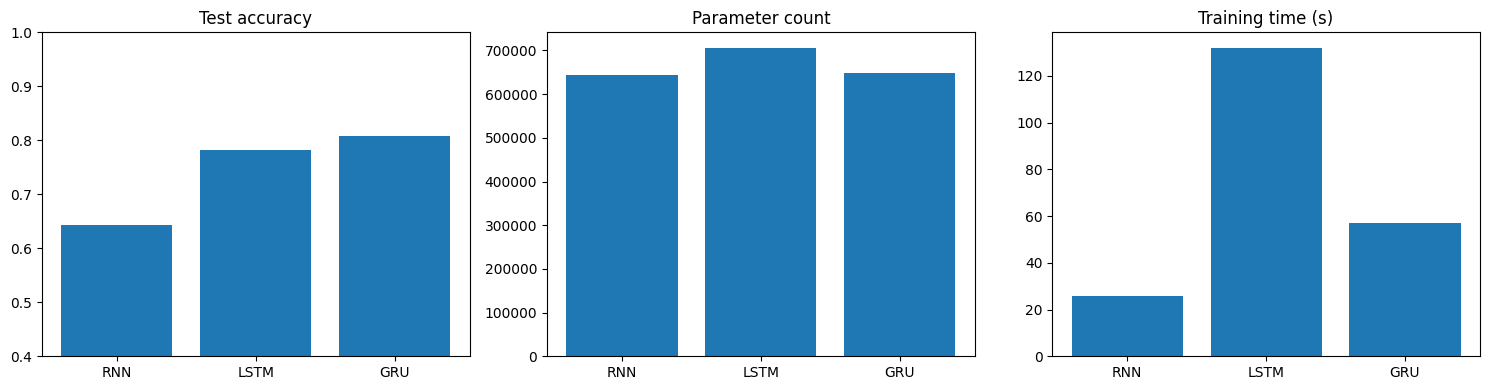

In [8]:
!pip install keras-tuner -q

"""Experiment 18: RNN, LSTM and GRU Hyperparameter Experimentation with KerasTuner (IMDB)"""
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import keras_tuner as kt                      # pip install keras-tuner

np.random.seed(42); tf.random.set_seed(42)
USE_SYNTHETIC = False        # keep False; True only generates random data to smoke-test the code
NUM_WORDS, MAXLEN = 10000, 200
N_TRAIN, N_TEST = 8000, 4000                  # subsets so that the search fits a small compute budget
MAX_TRIALS, SEARCH_EPOCHS, FINAL_EPOCHS = 4, 3, 4

# ---------------- Task 1: tokenise (IMDB is pre-tokenised), pad, embedding later ----------------
if USE_SYNTHETIC:
    x_train = np.random.randint(1, NUM_WORDS, (600, MAXLEN)); y_train = np.random.randint(0, 2, 600)
    x_test = np.random.randint(1, NUM_WORDS, (300, MAXLEN)); y_test = np.random.randint(0, 2, 300)
else:
    (x_train, y_train), (x_test, y_test) = keras.datasets.imdb.load_data(num_words=NUM_WORDS)
    x_train = keras.utils.pad_sequences(x_train[:N_TRAIN], maxlen=MAXLEN); y_train = y_train[:N_TRAIN]
    x_test = keras.utils.pad_sequences(x_test[:N_TEST], maxlen=MAXLEN); y_test = y_test[:N_TEST]
print("Train:", x_train.shape, "Test:", x_test.shape)

CELLS = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}

# ---------------- Tasks 2 & 3: model builder with tunable hyperparameters ----------------
def make_builder(cell_name):
    def build(hp):
        cell_name_hp = hp.Choice("cell", [cell_name])                     # cell type is a hyperparameter
        cell = CELLS[cell_name_hp]
        units = hp.Int("units", 32, 128, step=32)
        n_layers = hp.Int("rnn_layers", 1, 2)
        dropout = hp.Float("dropout", 0.0, 0.5, step=0.1)
        lr = hp.Float("lr", 1e-4, 1e-2, sampling="log")
        emb = hp.Choice("embedding_dim", [32, 64, 128])
        m = keras.Sequential([layers.Input((MAXLEN,)), layers.Embedding(NUM_WORDS, emb)])
        for i in range(n_layers):
            m.add(cell(units, return_sequences=(i < n_layers - 1)))
            m.add(layers.Dropout(dropout))
        m.add(layers.Dense(1, activation="sigmoid"))
        m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
        return m
    return build

# ---------------- Tasks 3-5: search each cell type, retrain best, compare ----------------
rows, best_configs = [], {}
for name in CELLS:
    tuner = kt.RandomSearch(make_builder(name), objective="val_accuracy", max_trials=MAX_TRIALS,
                            directory="kt_logs", project_name=f"imdb_{name}", overwrite=True, seed=42)
    t0 = time.time()
    tuner.search(x_train, y_train, validation_split=0.2, epochs=SEARCH_EPOCHS, batch_size=64, verbose=0)
    search_time = time.time() - t0

    best_hp = tuner.get_best_hyperparameters(1)[0]
    best_configs[name] = {k: best_hp.get(k) for k in ["units", "rnn_layers", "dropout", "lr", "embedding_dim"]}
    print(f"\n[{name}] best hyperparameters: {best_configs[name]}")

    model = tuner.hypermodel.build(best_hp)                                # retrain best config
    t0 = time.time()
    model.fit(x_train, y_train, validation_split=0.2, epochs=FINAL_EPOCHS, batch_size=64, verbose=0)
    train_time = time.time() - t0
    test_acc = model.evaluate(x_test, y_test, verbose=0)[1]
    rows.append({"Cell": name, **best_configs[name], "Params": model.count_params(),
                 "Search time (s)": round(search_time, 1), "Final train time (s)": round(train_time, 1),
                 "Test accuracy": round(test_acc, 4)})
    print(f"[{name}] test accuracy = {test_acc:.4f}, params = {model.count_params():,}, train time = {train_time:.1f}s")

table = pd.DataFrame(rows).set_index("Cell")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
print("\n", table)
table.to_csv("kerastuner_results.csv")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(table.index, table["Test accuracy"]); ax[0].set_title("Test accuracy"); ax[0].set_ylim(0.4, 1.0)
ax[1].bar(table.index, table["Params"]); ax[1].set_title("Parameter count")
ax[2].bar(table.index, table["Final train time (s)"]); ax[2].set_title("Training time (s)")
plt.tight_layout(); plt.show()